# Week 10B — Learning from a Frozen Experience Dataset
## Offline Reinforcement Learning: BC → Fitted Q-Learning → Conservative Q-Learning
**CSCI 4932/5933 · Fall 2026 · Instructor demonstration and student exploration**

**Lecture questions**
1. If a dataset already contains `(state, action, reward, next_state)`, can we improve on the original behavior **without new training interactions**?
2. Why might an ordinary Q-learner select actions rarely or never represented in that dataset?
3. How can a conservative objective reduce (not eliminate) this problem?

**Runnable prerequisites:** Python, NumPy, PyTorch, Pandas, Matplotlib. No Gymnasium installation or external dataset is required. The real-world example is **inventory replenishment** with order delays and uncertain demand. It complements the Week 10A CartPole imitation-learning notebook and Week 10 traffic lab.

**Course boundary:** The simulator generates logs *before training* and evaluates the learned policies *after training*. The training algorithms never step the simulator; they only read the frozen dataset. Simulation-based evaluation is not offline policy evaluation from real historical data.

## Part 1 — Three learning settings (discussion: 5–8 minutes)

| Question | Behavior Cloning | Online PPO / Q-learning | Offline RL |
|---|---|---|---|
| Training input | `(s, a_expert)` | Newly sampled experience | Fixed `(s,a,r,s',done)` |
| Uses reward? | Not directly | Yes | Yes |
| Collects new experience during training? | No | Yes | **No** |
| Principal risk | Compounding imitation errors | Exploration cost/safety | Unsupported-action value errors |

**Ask:** Can you think of a real system where you cannot simply deploy a randomly exploring policy? Consider clinical care, factories, energy storage, and school interventions.

**The offline Bellman regression target** for a terminal-marked transition is

$$y_i=r_i+\gamma(1-d_i)\max_{a'}Q_{\bar\theta}(s'_i,a').$$

`d_i` marks a genuinely terminal finite-horizon episode in our toy simulator. Gymnasium's *external time-limit truncations* and genuine terminations require different handling in some continuing-task settings.

## Part 2 — The unsupported-action trap (5 minutes)

Suppose our fixed dataset frequently contains `keep current action`, but never contains `expedite an order` in a particular urgent state. A neural Q-function can still output a large value for `expedite` there. The value is an **estimate**, not evidence.

The following numerical values are a constructed illustration of an estimation error—not values learned from the dataset below.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from copy import deepcopy

np.random.seed(12)
torch.manual_seed(12)
torch.set_num_threads(1)  # predictable CPU performance

pd.DataFrame({
    "Action": ["No order", "Order 4", "Order 8"],
    "Seen in this state?": ["Many times", "Occasionally", "Never"],
    "Illustrative predicted Q": [-5.0, -3.0, 12.0]
})

,Action,Seen in this state?,Illustrative predicted Q
0,No order,Many times,-5.0
1,Order 4,Occasionally,-3.0
2,Order 8,Never,12.0


**Think–pair–share:** The greedy action is `Order 8`—but do we have data to trust its value? What happens when `max_a Q(s,a)` repeatedly prefers actions unsupported by the dataset?

This is part of the **extrapolation / distribution-shift problem**. Fixed data restrict what can be learned confidently. More epochs cannot create evidence for missing state-action regions.

## Part 3 — Real-world demo: a bookstore inventory manager (10 minutes)

A campus bookstore must decide how many units to order each morning.

- **State** = `[in-stock items, items arriving today, yesterday's demand, announced demand forecast, day fraction]`.
- **Actions** = order 0, 4, or 8 more units for **tomorrow**.
- **Outcome** = items sold, unsatisfied demand, remaining inventory.
- **Reward** = sales revenue − procurement cost − holding cost − stockout penalty − fixed ordering fee.
- **Episode** = 30 business days, a deliberately finite planning horizon.

The demo simulator uses random Poisson demand and an imperfect heuristic ordering manager. It is fictional: no actual bookstore records are used.

**Ask:** Why can a manager's action be locally sensible but globally suboptimal? Why must we include pending deliveries in the state?

In [2]:
ACTIONS = np.array([0, 4, 8], dtype=np.int64)
HORIZON = 30

class Bookstore:
    """Small transparent finite-horizon decision problem; Gym-like but standalone."""
    def __init__(self, scenario="train", horizon=HORIZON):
        self.scenario = scenario
        self.horizon = horizon
        self.rng = None

    def reset(self, seed=0):
        self.rng = np.random.default_rng(seed)
        self.day = 0
        self.stock = int(self.rng.integers(2, 11))
        self.arriving = int(self.rng.choice(ACTIONS))
        self.last_demand = 3.0
        self.forecast = self._forecast()
        return self.observation()

    def _forecast(self):
        if self.scenario == "surge":
            return 7.5 if self.day >= 10 else 4.0
        return float(self.rng.choice([2.0, 4.0, 6.0], p=[.3, .5, .2]))

    def observation(self):
        # All inputs are known at decision time (no future actual demand is revealed).
        return np.array([
            self.stock/20, self.arriving/8, self.last_demand/12,
            self.forecast/8, self.day/self.horizon
        ], dtype=np.float32)

    def step(self, action_index):
        order = int(ACTIONS[int(action_index)])
        available = self.stock + self.arriving
        demand = int(self.rng.poisson(self.forecast))
        sold = min(available, demand)
        shortage = max(0, demand-available)
        self.stock = available - sold
        self.arriving = order  # today's order arrives NEXT day
        reward = (
            6.0*sold - 2.5*order - 0.40*self.stock
            - 4.0*shortage - (1.0 if order > 0 else 0.0)
        )
        self.last_demand = float(demand)
        self.day += 1
        done = self.day >= self.horizon
        if not done:
            self.forecast = self._forecast()
        info = {"demand": demand, "sold": sold, "shortage": shortage,
                "inventory": self.stock, "order": order}
        return self.observation(), float(reward), done, info


def heuristic_action(obs, rng, explore=0.18):
    # Approximate stock-position target with modest inventory buffer.
    stock = obs[0] * 20
    arriving = obs[1] * 8
    forecast = obs[3] * 8
    target = 2.0 * forecast + 2
    shortage = max(0, target - (stock + arriving))
    action = int(np.argmin(np.abs(ACTIONS - shortage)))
    if rng.random() < explore:
        action = int(rng.integers(len(ACTIONS)))
    return action

# An example trajectory (no policy is learned yet)
example = Bookstore()
s = example.reset(seed=11)
rng = np.random.default_rng(11)
rows = []
for t in range(6):
    a = heuristic_action(s, rng)
    sp, r, done, info = example.step(a)
    rows.append({"day":t, "in_stock":round(s[0]*20),
                 "forecast":round(s[3]*8, 1), "order":int(ACTIONS[a]),
                 "actual_demand":info['demand'], "reward":round(r,1)})
    s = sp
pd.DataFrame(rows)

,day,in_stock,forecast,order,actual_demand,reward
0,0,3,4.0,8,1,-15.8
1,1,2,2.0,0,1,2.4
2,2,9,2.0,4,3,4.6
3,3,6,4.0,4,4,10.6
4,4,6,6.0,8,7,19.8
5,5,3,6.0,8,4,0.2


## Part 4 — Collect once, then **freeze** the dataset (10 minutes)

To prevent accidental online learning, the simulator is used only in the collection function. **Every training function below accepts arrays—not an environment.**

We split **by episode**, not by individual transition, so highly correlated neighbors from the same trajectory do not appear in both training and validation data.

The fixed dataset includes `done` so value backups do not extend past episode boundaries.

In [3]:
def collect_episodes(n_episodes=220, epsilon=0.18, base_seed=4000):
    episodes=[]
    for ep in range(n_episodes):
        env=Bookstore("train")
        state=env.reset(seed=base_seed+ep)
        rng=np.random.default_rng(base_seed+100000+ep)
        trajectory=[]
        while True:
            action=heuristic_action(state, rng, explore=epsilon)
            next_state, reward, done, info=env.step(action)
            trajectory.append((state.copy(), action, reward/10.0,
                               next_state.copy(), float(done)))
            state=next_state
            if done: break
        episodes.append(trajectory)
    return episodes


def flatten(episodes):
    tr=[record for episode in episodes for record in episode]
    s=np.stack([r[0] for r in tr]).astype('float32')
    a=np.array([r[1] for r in tr],dtype='int64')
    r=np.array([r[2] for r in tr],dtype='float32')
    sp=np.stack([r[3] for r in tr]).astype('float32')
    d=np.array([r[4] for r in tr],dtype='float32')
    return s,a,r,sp,d

episodes = collect_episodes()
train_eps, valid_eps = episodes[:180], episodes[180:]
D=flatten(train_eps)              # frozen training transitions
D_valid=flatten(valid_eps)        # held-out log validation transitions
print('Training transitions:',len(D[0]))
print('Validation transitions:',len(D_valid[0]))
print('Logged actions (order units):',
      {int(ACTIONS[a]): int((D[1]==a).sum()) for a in range(3)})
print('First logged transition:')
print('s=',D[0][0], 'a=',ACTIONS[D[1][0]],
      'reward=',round(float(D[2][0]*10),2),'s_next=',D[3][0],
      'done=',bool(D[4][0]))

Training transitions: 5400
Validation transitions: 1200
Logged actions (order units): {0: 2413, 4: 1852, 8: 1135}
First logged transition:
s= [0.45 0.5  0.25 0.75 0.  ] a= 0 reward= 26.8 s_next= [0.4        0.         0.41666666 0.75       0.03333334] done= False


### Ask students

1. Why does the dataset contain both `s` and `s_next`?
2. Why does Behavior Cloning **not** need `reward` or `s_next`?
3. Why should we not use a random 80/20 transition split when adjacent records come from the same episode?
4. How would the experiment change if the original manager **never** ordered eight units?

## Part 5 — Baseline #1: Behavior Cloning (10 minutes)

This is the same methodology as Lecture 10A. Train a small classifier to predict the original manager's action, **without using rewards**.

In [4]:
class QNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net=nn.Sequential(nn.Linear(5,64),nn.ReLU(),
                               nn.Linear(64,64),nn.ReLU(),nn.Linear(64,3))
    def forward(self,x): return self.net(x)


def train_bc(dataset, steps=350, seed=1):
    torch.manual_seed(seed)
    model=QNet()
    optimizer=torch.optim.Adam(model.parameters(),lr=0.003)
    states, acts = dataset[0], dataset[1]
    x=torch.from_numpy(states); y=torch.from_numpy(acts)
    gen=torch.Generator().manual_seed(seed)
    for step in range(steps):
        idx=torch.randint(len(x),(256,),generator=gen)
        loss=F.cross_entropy(model(x[idx]), y[idx])
        optimizer.zero_grad(); loss.backward(); optimizer.step()
    return model.eval()

bc_model=train_bc(D)
with torch.no_grad():
    val_logits=bc_model(torch.from_numpy(D_valid[0]))
    val_accuracy=(val_logits.argmax(1).numpy()==D_valid[1]).mean()
print(f'Behavior Cloning held-out action agreement: {val_accuracy:.1%}')

Behavior Cloning held-out action agreement: 87.2%


**Interpret carefully:** Held-out imitation accuracy measures agreement with the logging policy on logged states. It is not profit, return, or safety. The manager itself occasionally took random actions, so 100% agreement is neither expected nor necessarily desirable.

## Part 6 — Baseline #2: Naive fixed-batch deep Q-learning (15 minutes)

We now **use recorded rewards**. For each transition in `D`, minimize a Bellman regression loss. The Q-model outputs a value for **every action**, even if the dataset contains little evidence for some actions.

$$L_{\mathrm{TD}}=\mathbb{E}_{(s,a,r,s',d)\sim D}\left[\operatorname{Huber}\Big(Q_\theta(s,a)-\underbrace{[r+\gamma(1-d)\max_{a'} Q_{\bar\theta}(s',a')]}_{\text{frozen-target backup}}\Big)\right].$$

This is a **didactic fixed-batch DQN / fitted-Q approximation**, not a claim that naive DQN is a reliable offline RL algorithm. The target network and Huber loss help numerical training; they do not fix missing coverage.

In [5]:
def train_offline_q(dataset, steps=850, gamma=.95, alpha=0.0, seed=7):
    """Static-dataset Q updates. alpha=0: naive; alpha>0: CQL-style regularizer."""
    torch.manual_seed(seed)
    x,a,r,xp,d=map(torch.from_numpy,dataset)
    q=QNet(); target=deepcopy(q).eval()
    opt=torch.optim.Adam(q.parameters(),lr=0.001)
    gen=torch.Generator().manual_seed(seed)
    history=[]

    for step in range(steps):
        ids=torch.randint(len(x),(256,),generator=gen)
        s_b,a_b,r_b,sp_b,d_b=(v[ids] for v in [x,a,r,xp,d])
        with torch.no_grad():
            y=r_b + gamma*(1.0-d_b)*target(sp_b).max(dim=1).values
        all_q=q(s_b)
        q_logged=all_q.gather(1,a_b[:,None]).squeeze(1)
        td=F.smooth_l1_loss(q_logged,y)
        # Discrete conservative regularizer: discourage high Q over all actions
        # relative to Q on logged actions. CQL-style, simplified small-scale example.
        conservative=(torch.logsumexp(all_q,dim=1)-q_logged).mean()
        loss=td + alpha*conservative
        opt.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(q.parameters(),5.0)
        opt.step()
        if (step+1)%100==0: target.load_state_dict(q.state_dict())
        if (step+1)%50==0:
            history.append((step+1,float(td.item()),float(conservative.item())))
    return q.eval(),pd.DataFrame(history,columns=['step','td_loss','conservative_penalty'])

q_naive, hist_naive=train_offline_q(D, alpha=0.0)
print('Naive offline Q fitted from',len(D[0]),'stored transitions.')
print(hist_naive.tail(3).to_string(index=False))

Naive offline Q fitted from 5400 stored transitions.
 step  td_loss  conservative_penalty
  750 0.511721              1.146371
  800 0.339986              1.115486
  850 0.313103              1.188458


## Part 7 — Conservative Q-Learning: what's the extra term? (15 minutes)

A conservative Q objective supplements Bellman fitting with an incentive to keep values of arbitrary actions relatively low compared with **logged** actions:

$$L_{\mathrm{offline}}=L_{\mathrm{TD}}+\alpha\left(\mathbb E_{s\sim D}\left[\log\sum_a\exp Q_\theta(s,a)\right]-\mathbb E_{(s,a)\sim D}[Q_\theta(s,a)]\right).$$

This notebook implements **a small discrete-action CQL-style objective**, not a full reproduction of all CQL variants or their guarantees. Note that `logsumexp` does *not* simply mask unseen actions: it changes the learned value estimates through a regularizer. The result depends on data coverage, tuning, and the function approximator.

**Student thought question:** If `alpha` becomes extremely large, might the model become too conservative to improve on the logged controller?

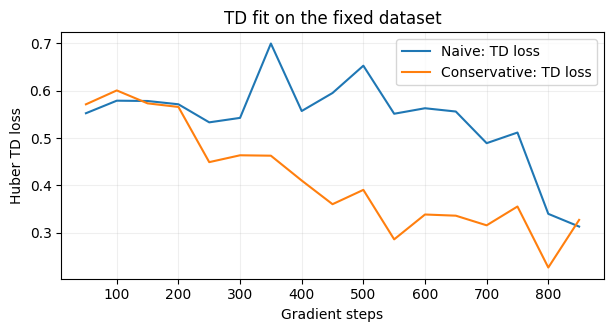

Note: lower training TD error does not guarantee higher policy return.


In [6]:
q_conservative,hist_cql=train_offline_q(D,alpha=0.35,seed=7)
fig,ax=plt.subplots(figsize=(7,3.2))
ax.plot(hist_naive.step,hist_naive.td_loss,label='Naive: TD loss')
ax.plot(hist_cql.step,hist_cql.td_loss,label='Conservative: TD loss')
ax.set(xlabel='Gradient steps',ylabel='Huber TD loss',title='TD fit on the fixed dataset')
ax.legend(); ax.grid(alpha=.2)
plt.show()
print('Note: lower training TD error does not guarantee higher policy return.')

## Part 8 — Evaluate the learned decisions in **held-out simulation** (15 minutes)

Evaluation uses a new simulator instance *after* the models are trained. This is appropriate for our known toy world, but not proof of safe improvement from retrospective real-world logs.

Measures:
- **Mean episode return** (higher is better)
- **Unfilled demand units** (lower is better)
- **Mean ending inventory** (indicates over-ordering)

All policies are evaluated on the same held-out seeds, allowing paired comparisons.

                  mean_return  sd_return  avg_unfilled  avg_ending_stock  avg_fill_rate  avg_ordered
policy                                                                                              
Random                  99.25     124.03          7.54             24.14           0.94       122.86
Heuristic              232.10      42.54         16.57              2.66           0.86        91.49
Behavior Cloning       233.14      42.34         16.41              2.61           0.86        91.54
Naive Offline Q       -551.79     318.16          4.33            109.16           0.96       214.91
Conservative Q         237.38      38.84         15.60              2.77           0.87        92.51


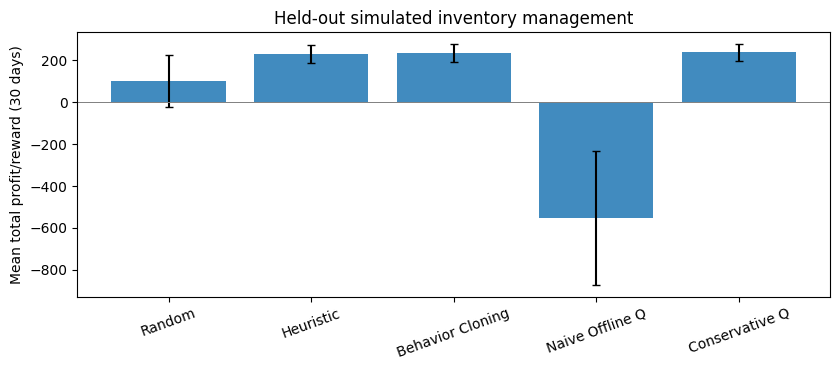

In [7]:
def model_action(model, observation):
    with torch.no_grad():
        return int(model(torch.from_numpy(observation).view(1,-1)).argmax(1).item())

def evaluate(policy_name,model=None,scenario='train',seeds=range(7000,7070)):
    results=[]
    for seed in seeds:
        env=Bookstore(scenario)
        s=env.reset(seed=seed)
        rng=np.random.default_rng(seed+900000)
        total=0.0; missed=0; total_demand=0; total_ordered=0
        while True:
            if policy_name=='heuristic':
                a=heuristic_action(s,rng, explore=0.0)
            elif policy_name=='random':
                a=int(rng.integers(3))
            else:
                a=model_action(model,s)
            s,reward,done,info=env.step(a)
            total+=reward
            missed+=info['shortage']
            total_demand+=info['demand']; total_ordered+=info['order']
            if done: break
        results.append({'seed':seed, 'return':total,
                        'unfilled':missed,'ending_stock':env.stock,
                        'fill_rate':1.0-missed/max(1,total_demand),
                        'units_ordered':total_ordered})
    return pd.DataFrame(results)

models={'Random':('random',None),'Heuristic':('heuristic',None),
        'Behavior Cloning':('model',bc_model),
        'Naive Offline Q':('model',q_naive),
        'Conservative Q':('model',q_conservative)}

def evaluate_all(scenario='train'):
    frames=[]
    for name,(which,m) in models.items():
        frame=evaluate(which,m,scenario)
        frame['policy']=name
        frames.append(frame)
    return pd.concat(frames,ignore_index=True)

eval_standard=evaluate_all('train')
summary=eval_standard.groupby('policy',sort=False).agg(
    mean_return=('return','mean'),sd_return=('return','std'),
    avg_unfilled=('unfilled','mean'),avg_ending_stock=('ending_stock','mean'),
    avg_fill_rate=('fill_rate','mean'),avg_ordered=('units_ordered','mean'))
print(summary.round(2).to_string())

fig,ax=plt.subplots(figsize=(8.5,3.8))
ax.bar(summary.index, summary.mean_return, yerr=summary.sd_return,
       capsize=3,alpha=.85)
ax.axhline(0,linewidth=.7,color='gray')
ax.set(ylabel='Mean total profit/reward (30 days)',
       title='Held-out simulated inventory management')
ax.tick_params(axis='x',rotation=20)
plt.tight_layout();plt.show()

### Crucial interpretation checkpoint

The conservative method is **not required to win**. No offline RL objective can compensate for missing evidence or a poorly specified model. Ask:

1. Did Behavior Cloning imitate the imperfect manager effectively?
2. Did reward-based learning improve total return? Which method had the highest *variance*?
3. If naive offline Q scores higher in this experiment, does that disprove the offline RL coverage problem? Why not?
4. Which environment features are necessary to trust the results in a real bookstore?

## Part 9 — Out-of-distribution demand (10 minutes)

Evaluate policies on a **surge** scenario not represented by the normal training forecasts. This measures an important deployment risk: distribution shift.

                  mean_return  avg_unfilled  avg_fill_rate  surge_return  surge_unfilled  surge_fill_rate
policy                                                                                                   
Random                  99.25          7.54           0.94        149.19           61.47             0.68
Heuristic              232.10         16.57           0.86        472.73           18.64             0.90
Behavior Cloning       233.14         16.41           0.86        442.63           23.16             0.88
Naive Offline Q       -551.79          4.33           0.96         50.78           23.84             0.88
Conservative Q         237.38         15.60           0.87        459.34           20.39             0.89


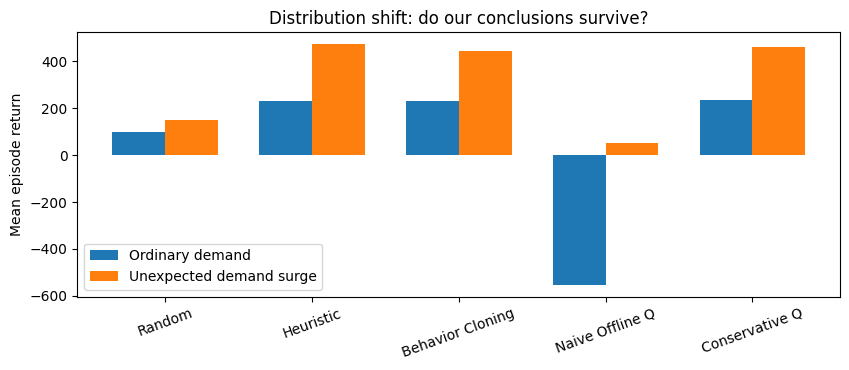

In [8]:
eval_shift=evaluate_all('surge')
change=eval_shift.groupby('policy',sort=False).agg(
    surge_return=('return','mean'), surge_unfilled=('unfilled','mean'),
    surge_fill_rate=('fill_rate','mean'))
compare=summary[['mean_return','avg_unfilled','avg_fill_rate']].join(change)
print(compare.round(2).to_string())

fig,ax=plt.subplots(figsize=(8.6,3.8))
w=.36; pos=np.arange(len(compare))
ax.bar(pos-w/2,compare.mean_return,w,label='Ordinary demand')
ax.bar(pos+w/2,compare.surge_return,w,label='Unexpected demand surge')
ax.set_xticks(pos,compare.index,rotation=20)
ax.set_ylabel('Mean episode return')
ax.set_title('Distribution shift: do our conclusions survive?')
ax.legend(); plt.tight_layout();plt.show()

## Part 10 — Dataset coverage: count the actions (5–8 minutes)

For simplicity, group logged examples by forecast regime. Different forecast regimes are not complete states; coverage also depends on stock, arriving orders, recent demand, and time. Nevertheless, even this coarse visualization can reveal action imbalance.

Ordered units       0     4    8
Demand forecast                 
2                1296   278   85
4                 996  1248  463
6                 121   326  587


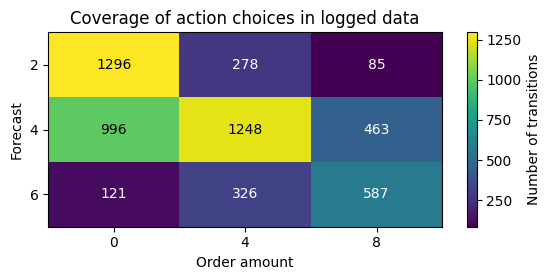

In [9]:
coverage = pd.crosstab(
    pd.Series(np.round(D[0][:,3]*8).astype(int),name='Demand forecast'),
    pd.Series(ACTIONS[D[1]],name='Ordered units')
)
print(coverage.to_string())
fig,ax=plt.subplots(figsize=(5.7,2.9))
im=ax.imshow(coverage.values,aspect='auto')
ax.set_xticks(range(len(coverage.columns)),coverage.columns)
ax.set_yticks(range(len(coverage.index)),coverage.index)
ax.set(xlabel='Order amount',ylabel='Forecast',title='Coverage of action choices in logged data')
for i in range(coverage.shape[0]):
    for j in range(coverage.shape[1]):
        ax.text(j,i,int(coverage.iloc[i,j]),ha='center',va='center',color='white' if coverage.iloc[i,j]<coverage.values.max()*.55 else 'black')
fig.colorbar(im,ax=ax,label='Number of transitions')
plt.tight_layout();plt.show()

## Part 11 — Student experiments (20–30 minutes outside lecture)

**Experiment A: coverage.** Set `epsilon=0` in `collect_episodes`, then repeat with `epsilon=0.35`. Train and evaluate the same two Q methods on each frozen dataset. Keep the evaluation seeds and training budgets fixed. Does greater action diversity always mean higher-quality data?

**Experiment B: conservatism.** Change `alpha` from `0.0 → 0.1 → 0.35 → 1.0` and compare return, stockouts, and action frequencies. (An excessively large value may reduce performance.)

**Experiment C: reward engineering.** Double the penalty for unsatisfied demand and articulate what tradeoff should change. Do **not** claim to have learned a policy for the new reward using the old dataset unless you can recompute rewards from stored transition details; as provided, the fixed transition tuple contains only original scalar rewards. For a controlled experiment, regenerate and freeze a new dataset with the modified reward.

**Experiment D (graduate extension):** Investigate whether a support mask estimated from state-action counts differs from the CQL-style penalty in its effect on unseen actions. Explain why discretizing continuous states has limitations.

**Methodology rules:** Keep evaluation seeds fixed, report ≥3 training seeds when practical, separate training from validation, do not tune to the held-out evaluation set, and do not present simulator-only evaluation as a valid safety guarantee for real deployments.

## Part 12 — Reflection / mini-assessment

1. **Multiple choice:** Which quantity is new in offline RL relative to BC? A. Expert action labels only. B. Recorded rewards and next states. C. New online trial-and-error. **Answer: B.**
2. **Short answer:** Why might a Q-network assign the greatest estimated value to an action absent from the dataset? **Answer:** Approximation and bootstrapping can lead to unsupported-action overestimation; no observed evidence necessarily constrains that value.
3. **Multiple choice:** What does the CQL-style penalty discourage? A. High values for arbitrary actions relative to logged actions. B. All nonzero rewards. C. Future rewards. **Answer: A.**
4. **Short answer:** Why is the logged action-prediction accuracy of BC insufficient to establish superior sequential control? **Answer:** Accuracy on logged states does not measure long-horizon return or performance under states visited by the learner.
5. **Short answer:** Why can we evaluate using the simulator after training but not simply run the learned policy on live city traffic? **Answer:** The simulator is a controlled evaluation model; real deployment involves unknown dynamics, safety risks, distribution shift, and would require validation beyond offline data.
6. **Challenge:** Can offline RL safely outperform the data-collecting policy when important actions were never tried? **Answer:** Not reliably from the logged evidence alone; improvements require adequate coverage and assumptions/validation.

**Exit ticket:** “How does using `max_a Q(s,a)` become dangerous when only a small subset of actions has been observed?”

## Reference readings (verified October 2026)

- **Levine, Kumar, Tucker & Fu (2020)** — [Offline Reinforcement Learning: Tutorial, Review, and Perspectives on Open Problems](https://arxiv.org/abs/2005.01643). Student reading: Introduction and the sections explaining the offline RL challenge.
- **Kumar, Zhou, Tucker & Levine (2020)** — [Conservative Q-Learning for Offline Reinforcement Learning](https://arxiv.org/abs/2006.04779). Graduate reading: key motivation and discrete conservative penalty.
- **Farama Foundation — [Minari](https://minari.farama.org/)**. Standard format, hosting and sampling for offline RL datasets; optional transition from toy CSV arrays to shareable logged trajectories.
- **[d3rlpy](https://d3rlpy.readthedocs.io/)**. Research-oriented implementations of BC, CQL, and other offline RL methods; optional advanced lab.

**Next week:** From one inventory manager or one traffic light to many decision-makers: Multi-Agent Reinforcement Learning, shared resources, competing objectives and non-stationarity.